# Analisis Segmentasi Spesies Penguin Menggunakan K-Means Clustering
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah pusat konservasi margasatwa dan peneliti biologi kelautan ingin membangun sistem kecerdasan buatan berbasis Unsupervised Machine Learning untuk mengelompokkan karakteristik fisik populasi penguin secara otomatis ke dalam beberapa klaster kelompok morfologi tanpa perlu melakukan identifikasi manual secara terus-menerus di lapangan.
2. **Masalah**: Pusat konservasi tersebut masih mengelompokkan karakteristik fisik populasi penguin secara manual yang memakan waktu dan tenaga kerja.
3. **Solusi**: Membangun model *machine learning* berbasis algoritma **K-Means** untuk mengelompokkan populasi penguin secara otomatis dengan memanfaatkan dataset yang merekam berbagai ukuran anatomi tubuh penguin yang dimiliki oleh pusat konservasi tersebut.

### 1.2 Deskripsi Kolom Dataset `penguins.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `culmen_length_mm` | `float64` | Panjang paruh penguin (culmen length) (satuan: milimeter). |
| `culmen_depth_mm` | `float64` | Kedalaman paruh penguin (culmen depth) (satuan: milimeter). |
| `flipper_length_mm` | `float64` | Panjang sirip penguin (flipper length) (satuan: milimeter). |
| `body_mass_g` | `float64` | Berat badan penguin (satuan: gram). |
| `sex` | `str` | Jenis kelamin penguin (MALE / FEMALE). |

---
## 2. Data Preparation

### 2.1 Import Library

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [95]:
df = pd.read_csv('penguins.csv', na_values=["NA", "NaN", ".", ""])
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Data Terbawah

In [96]:
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [97]:
df.tail()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0,FEMALE
341,50.4,15.7,222.0,5750.0,MALE
342,45.2,14.8,212.0,5200.0,FEMALE
343,49.9,16.1,213.0,5400.0,MALE


### 2.4 Tampilkan Informasi Data

In [98]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                334 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Dupliakt

In [99]:
print(f'Dimensi Kolom: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Missing Value: {df.isnull().sum().sum()}')
print(f'---- Missing Value Pada Setiap olom ----\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nData Duplikat: {df.duplicated().sum()}')

Dimensi Kolom: (344, 5)
Jumlah Data: 1720

Jumlah Missing Value: 18
---- Missing Value Pada Setiap olom ----
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Data Duplikat: 1


---
## 3. Explaratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [100]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


### 3.2 Memeriksa Outlier dengan IQR dan Z-Score

In [101]:
outliers = []

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        median = df[col].median()
        mean = df[col].mean()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        

pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,culmen_length_mm,43.921930,5.459584,32.1,39.225,44.45,48.50,59.6,25.3125,62.4125,0,0
1,culmen_depth_mm,17.151170,1.974793,13.1,15.600,17.30,18.70,21.5,10.9500,23.3500,0,0
2,flipper_length_mm,214.014620,260.558057,-132.0,190.000,197.00,213.75,5000.0,154.3750,249.3750,2,1
3,body_mass_g,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.00,6300.0,1750.0000,6550.0000,0,0


### 3.3 Visualisasi Outlier Dengan Bxplot

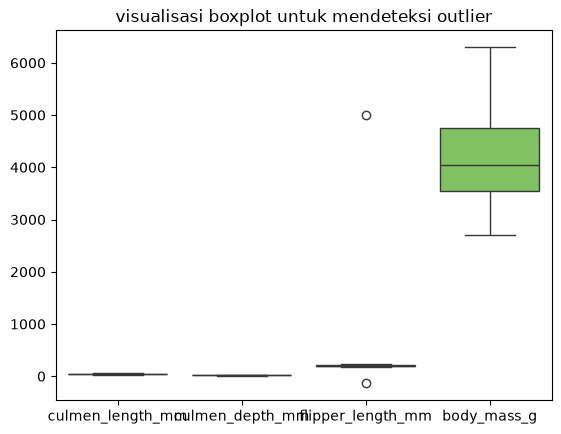

In [102]:
sns.boxplot(data=df[numeric_cols], palette='viridis')
plt.title('visualisasi boxplot untuk mendeteksi outlier')
plt.show()

### 3.4 Visualisasi Distribusi Data Pada Kolom Numerik

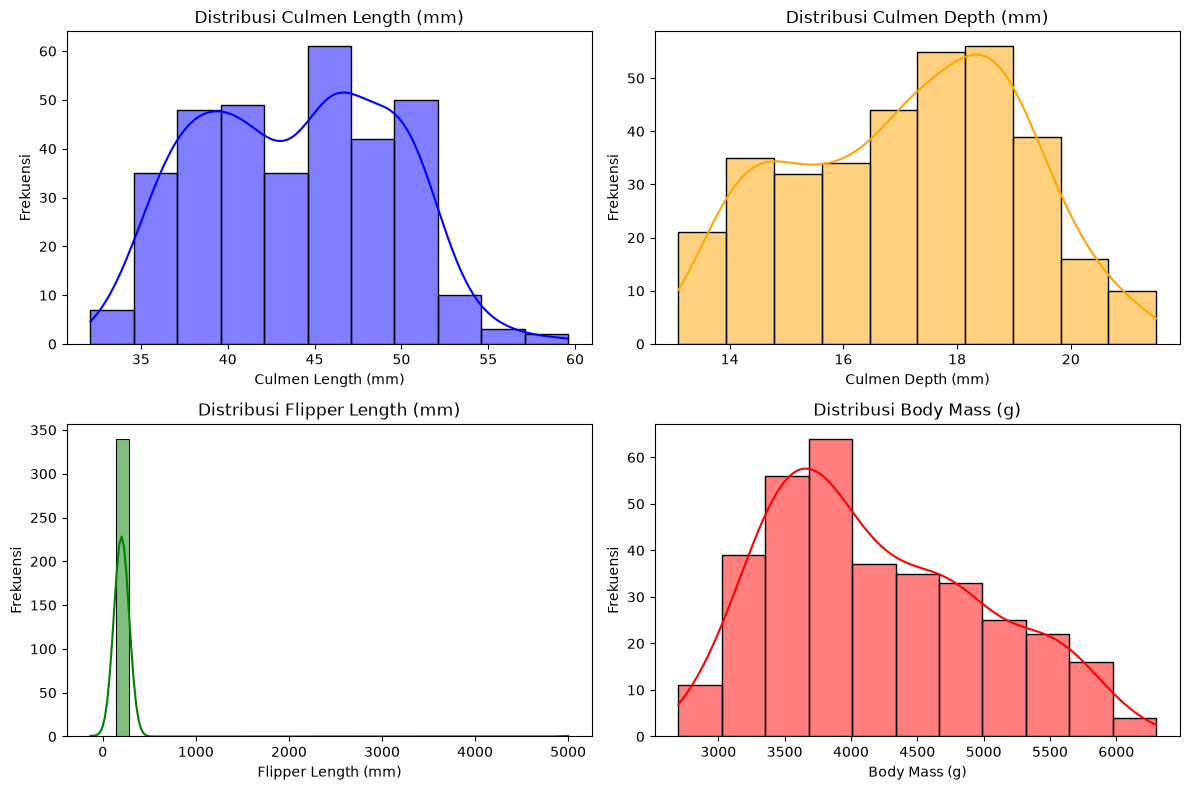

In [103]:
figure, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x='culmen_length_mm', kde=True, color='blue', ax=axes[0,0])
axes[0,0].set_title('Distribusi Culmen Length (mm)')
axes[0,0].set_xlabel('Culmen Length (mm)')
axes[0,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='culmen_depth_mm', kde=True, color='orange', ax=axes[0,1])
axes[0,1].set_title('Distribusi Culmen Depth (mm)')
axes[0,1].set_xlabel('Culmen Depth (mm)')
axes[0,1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='flipper_length_mm', kde=True, color='green', ax=axes[1,0])
axes[1,0].set_title('Distribusi Flipper Length (mm)')
axes[1,0].set_xlabel('Flipper Length (mm)')
axes[1,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='body_mass_g', kde=True, color='red', ax=axes[1,1])
axes[1,1].set_title('Distribusi Body Mass (g)')
axes[1,1].set_xlabel('Body Mass (g)')
axes[1,1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### 3.5 Analisis Korelasi Data Numerik

In [104]:
var_list = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
korelasi = []

for i in range(len(var_list)):
    for j in range(i + 1, len(var_list)):
        var1 = var_list[i]
        var2 = var_list[j]
        clean_df = df[[var1, var2]].dropna()
        pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
        spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
        kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
        
        korelasi.append({
            'pasangan variabel': f'{var1} & {var2}',
            'korelasi pearson': pearson,
            'korelasi spearman': spearman,
            'korelasi kendall': kendall
        })
        
pd.DataFrame(korelasi)

,pasangan variabel,korelasi pearson,korelasi spearman,korelasi kendall
0,culmen_length_mm & culmen_depth_mm,-0.235053,-0.221749,-0.122850
1,culmen_length_mm & flipper_length_mm,0.022697,0.673734,0.484480
2,culmen_length_mm & body_mass_g,0.595110,0.583800,0.433359
3,culmen_depth_mm & flipper_length_mm,0.044643,-0.516687,-0.279936
4,culmen_depth_mm & body_mass_g,-0.471916,-0.432372,-0.195070
5,flipper_length_mm & body_mass_g,0.049355,0.833294,0.653700


### 3.6 Visualisasi Matriks Korelasi Dengan Heatmap

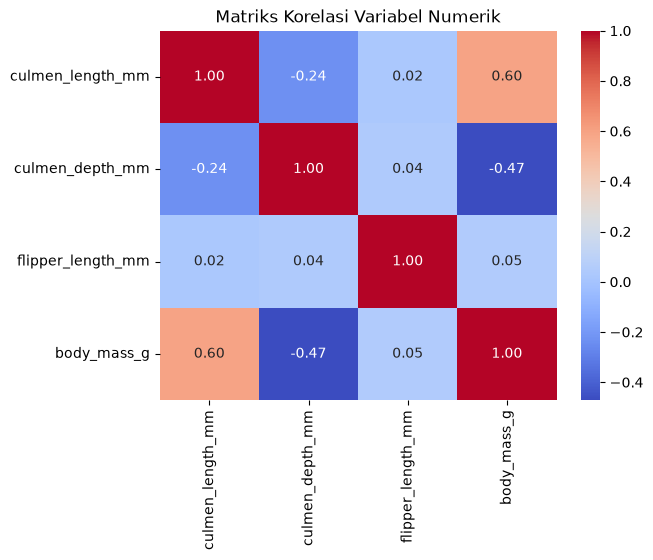

In [105]:
korelasi = df[var_list].corr(method='pearson')
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

### 3.7 Visualisasi Scatter Plot Panjang Paruh Dengan Kedalaman Paruh

<Axes: xlabel='culmen_length_mm', ylabel='culmen_depth_mm'>

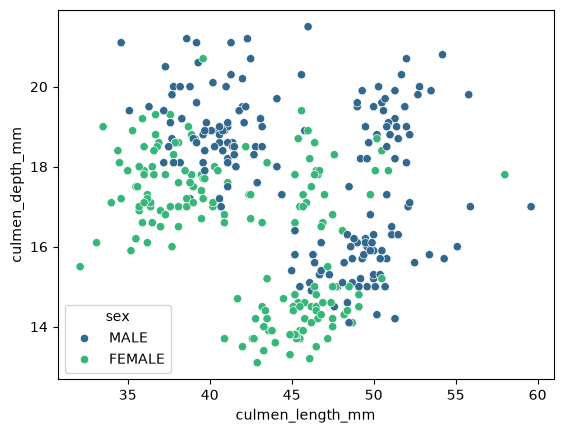

In [106]:
sns.scatterplot(data=df, x='culmen_length_mm', y='culmen_depth_mm', hue='sex', palette='viridis')

---

## 4. Data Preprocessing

### 4.1 Memeriksa dan Menangani Missing Value dan Duplikasi Data

In [107]:
print("--- Jumlah Missing Value ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df[df.duplicated()])

--- Jumlah Missing Value ---
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

--- Jumlah Duplikasi Data ---
     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
339               NaN              NaN                NaN          NaN  NaN


In [108]:
df = df.dropna(how='all')
df = df.drop_duplicates()
df = df.reset_index(drop=True)
print("--- Jumlah Missing Value Setelah Ditangani")
print(df.isnull().sum().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value Setelah Ditangani
8

--- Jumlah Duplikasi Data ---
0


### 4.2 Mengganti Missing Value pada Kolom `sex` dengan Menggunakan Unknown

In [109]:
df['sex'] = (df['sex'].astype('string').str.strip().replace({'': pd.NA, '.': pd.NA}))
df['sex'] = df['sex'].fillna("Unknown")
print(df['sex'].value_counts(dropna=False))
print("\nJumlah Missing Value: ", df.isnull().sum().sum())

sex
MALE       169
FEMALE     165
Unknown      8
Name: count, dtype: Int64

Jumlah Missing Value:  0


### 4.3 Memeriksa dan Menangani Outliers pada Seluruh Kolom Numerik

In [110]:
kolom_numerik = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)
    
    outliers = (df[col] < batas_bawah) | (df[col] > batas_atas)
    print(f"Outlier pada {col}: {outliers.sum()} baris")
    
    if outliers.sum() > 0:
        df.loc[outliers, col] = np.nan
        df[col] = df[col].fillna(df[col].median())

print("\nTotal Missing Value setelah penanganan outlier:", df.isnull().sum().sum())

Outlier pada culmen_length_mm: 0 baris
Outlier pada culmen_depth_mm: 0 baris
Outlier pada flipper_length_mm: 2 baris
Outlier pada body_mass_g: 0 baris

Total Missing Value setelah penanganan outlier: 0


### 4.4 Mengubah Kolom `sex` Menjadi Nilai Numerik Biner dan Memasukkan ke Dalam Kolom Fitur ($X$)

In [111]:
df_encoded = pd.get_dummies(df, columns=['sex'], prefix='sex', dtype=int)

print("Kolom Terbaru:", df_encoded.columns.tolist())

kolom_fitur = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex_FEMALE', 'sex_MALE', 'sex_Unknown']

X = df_encoded[kolom_fitur].copy()
print("Ukuran matriks fitur X:", X.shape)

Kolom Terbaru: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex_FEMALE', 'sex_MALE', 'sex_Unknown']
Ukuran matriks fitur X: (342, 7)


### 4.5 Melakukan Standardisasi pada Kolom Fitur 

In [112]:
mean_X = X.mean(axis=0)
std_X = X.std(axis=0, ddof=0)

X_scaled_df = (X - mean_X) / std_X

scaled_data = X_scaled_df.to_numpy()

X_scaled_df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_FEMALE,sex_MALE,sex_Unknown
count,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02
mean,1.662088e-16,-1.412775e-15,-8.310441e-16,4.155221e-17,9.349247e-17,-1.428357e-17,-2.597013e-17
std,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00
min,-2.168526e+00,-2.054446e+00,-2.062055e+00,-1.875362e+00,-9.655068e-01,-9.883717e-01,-1.547646e-01
25%,-8.615697e-01,-7.866355e-01,-7.791837e-01,-8.138982e-01,-9.655068e-01,-9.883717e-01,-1.547646e-01
50%,9.686524e-02,7.547549e-02,-2.802894e-01,-1.895079e-01,-9.655068e-01,-9.883717e-01,-1.547646e-01
75%,8.397670e-01,7.854492e-01,8.600404e-01,6.846384e-01,1.035725e+00,1.011765e+00,-1.547646e-01
max,2.875868e+00,2.205397e+00,2.142912e+00,2.620248e+00,1.035725e+00,1.011765e+00,6.461424e+00


---

## 5. Modelling

### 5.1 

In [113]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

### 5.2 

In [114]:
class KMeans:
    def __init__(self, K=3, max_iters=100, plot_steps=False):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps

        self.clusters = [[] for _ in range(self.K)]
        self.centroids = []

    def predict(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        random_sample_idxs = np.random.choice(self.n_samples, self.K, replace=False)
        self.centroids = [self.X[idx] for idx in random_sample_idxs]

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)

            if self.plot_steps:
                self.plot()

            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self._is_converged(centroids_old, self.centroids):
                break

            if self.plot_steps:
                self.plot()

        return self._get_cluster_labels(self.clusters)

    def predict_new(self, X):
        if len(self.centroids) != self.K:
            raise ValueError("Model K-Means belum dilatih.")

        labels = []
        for sample in X:
            labels.append(self._closest_centroid(sample, self.centroids))

        return np.array(labels, dtype=int)

    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples, dtype=int)
        for cluster_idx, cluster in enumerate(clusters):
            for sample_idx in cluster:
                labels[sample_idx] = cluster_idx
        return labels

    def _create_clusters(self, centroids):
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(sample, centroids)
            clusters[centroid_idx].append(idx)
        return clusters

    def _closest_centroid(self, sample, centroids):
        distances = [euclidean_distance(sample, point) for point in centroids]
        closest_idx = np.argmin(distances)
        return closest_idx

    def _get_centroids(self, clusters):
        centroids = np.zeros((self.K, self.n_features))
        for cluster_idx, cluster in enumerate(clusters):
            if len(cluster) > 0:
                cluster_mean = np.mean(self.X[cluster], axis=0)
                centroids[cluster_idx] = cluster_mean
            else:
                centroids[cluster_idx] = self.centroids[cluster_idx]
        return centroids

    def _is_converged(self, centroids_old, centroids):
        distances = [euclidean_distance(centroids_old[i], centroids[i]) for i in range(self.K)]
        return sum(distances) == 0

    def plot(self, feat_x=2, feat_y=3):
        fig, ax = plt.subplots(figsize=(8, 5))
        for i, index in enumerate(self.clusters):
            point = self.X[index][:, [feat_x, feat_y]].T
            ax.scatter(*point, label=f"Cluster {i}")

        for point in self.centroids:
            ax.scatter(point[feat_x], point[feat_y], marker="x", color="black", s=150, linewidth=3)

        ax.set_xlabel("Flipper Length (Scaled)")
        ax.set_ylabel("Body Mass (Scaled)")
        ax.legend()
        plt.show()

### 5.3 

In [115]:
np.random.seed(42)

K_pilihan = 3
kmeans_model = KMeans(K=K_pilihan, max_iters=100, plot_steps=False)
cluster_labels = kmeans_model.predict(scaled_data)

df['Cluster'] = cluster_labels

print(f"Model K-Means (K={K_pilihan}) berhasil dijalankan!")
print("\nDistribusi Jumlah Anggota per Cluster:")
print(df['Cluster'].value_counts().sort_index())

Model K-Means (K=3) berhasil dijalankan!

Distribusi Jumlah Anggota per Cluster:
Cluster
0    123
1    108
2    111
Name: count, dtype: int64


---

## 6. Evaluation

### 6.1

Jumlah Cluster K = 1 --> WCSS (SSE) = 2394.00
Jumlah Cluster K = 2 --> WCSS (SSE) = 1591.10
Jumlah Cluster K = 3 --> WCSS (SSE) = 1067.80
Jumlah Cluster K = 4 --> WCSS (SSE) = 766.22
Jumlah Cluster K = 5 --> WCSS (SSE) = 660.11
Jumlah Cluster K = 6 --> WCSS (SSE) = 318.75


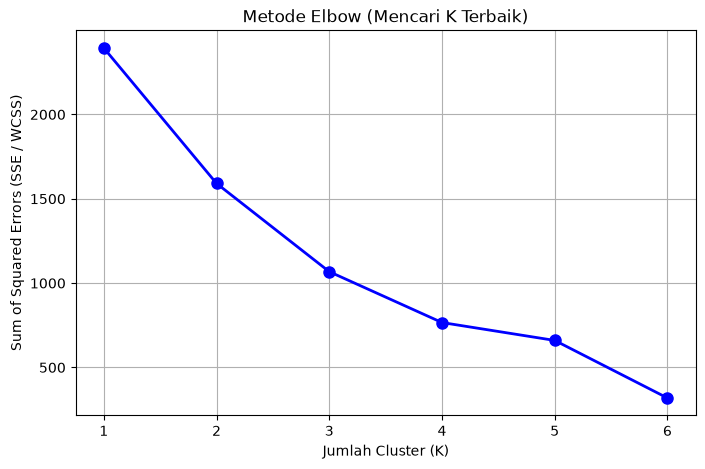

In [116]:
def hitung_wcss(X, labels, centroids):
    wcss = 0
    for i, centroid in enumerate(centroids):
        cluster_points = X[labels == i]
        if len(cluster_points) > 0:
            wcss += np.sum((cluster_points - centroid) ** 2)
    return wcss

ks = range(1, 7)
sse_list = []

for k in ks:
    np.random.seed(42)
    model_uji = KMeans(K=k, max_iters=100)
    labels_uji = model_uji.predict(scaled_data)
    nilai_sse = hitung_wcss(scaled_data, labels_uji, model_uji.centroids)
    sse_list.append(nilai_sse)
    print(f"Jumlah Cluster K = {k} --> WCSS (SSE) = {nilai_sse:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(ks, sse_list, 'bo-', linewidth=2, markersize=8)
plt.title('Metode Elbow (Mencari K Terbaik)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Sum of Squared Errors (SSE / WCSS)')
plt.grid(True)
plt.show()

Jumlah Cluster K = 2 --> Silhouette Score = 0.3768
Jumlah Cluster K = 3 --> Silhouette Score = 0.4462
Jumlah Cluster K = 4 --> Silhouette Score = 0.5348
Jumlah Cluster K = 5 --> Silhouette Score = 0.5199
Jumlah Cluster K = 6 --> Silhouette Score = 0.5679


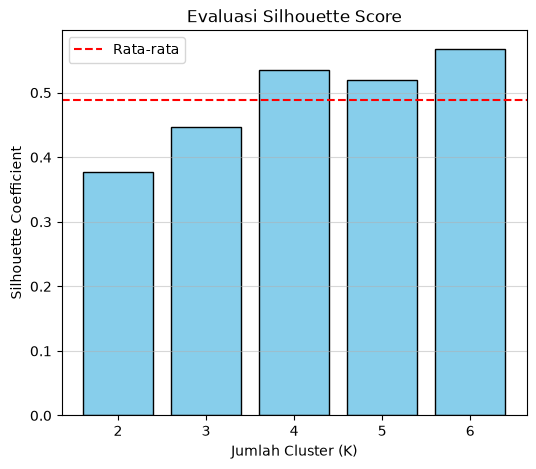

In [117]:
def hitung_silhouette_score(X, labels):
    n = len(X)
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0.0
    
    dist_matrix = np.sqrt(np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=2))
    
    s_scores = np.zeros(n)
    for i in range(n):
        own_cluster = labels[i]
        mask_own = (labels == own_cluster)
        mask_own[i] = False
        
        a_i = np.mean(dist_matrix[i, mask_own]) if np.sum(mask_own) > 0 else 0.0
        
        b_i = np.inf
        for other_cluster in unique_labels:
            if other_cluster != own_cluster:
                mask_other = (labels == other_cluster)
                if np.sum(mask_other) > 0:
                    mean_dist_other = np.mean(dist_matrix[i, mask_other])
                    b_i = min(b_i, mean_dist_other)
                    
        s_scores[i] = (b_i - a_i) / max(a_i, b_i) if max(a_i, b_i) > 0 else 0.0
        
    return np.mean(s_scores)

k_range_sil = range(2, 7)
silhouette_list = []

for k in k_range_sil:
    np.random.seed(42)
    model_uji = KMeans(K=k, max_iters=100)
    labels_uji = model_uji.predict(scaled_data)
    skor_sil = hitung_silhouette_score(scaled_data, labels_uji)
    silhouette_list.append(skor_sil)
    print(f"Jumlah Cluster K = {k} --> Silhouette Score = {skor_sil:.4f}")

plt.figure(figsize=(6, 5))
plt.bar(k_range_sil, silhouette_list, color='skyblue', edgecolor='black')
plt.axhline(y=np.mean(silhouette_list), color='red', linestyle='--', label='Rata-rata')
plt.title('Evaluasi Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Coefficient')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.show()

=== Tabel Posisi Centroid pada Skala Fisik Asli ===
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  \
0             47.50            14.98             217.19      5076.02   
1             43.78            19.14             194.81      4012.50   
2             40.09            17.62             188.88      3417.12   

   sex_FEMALE  sex_MALE  sex_Unknown  
0        0.47       0.5         0.03  
1       -0.00       1.0         0.00  
2        0.96      -0.0         0.04  

=== Profil Rata-Rata Fisik Penguin Tiap Cluster ===
         culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
Cluster                                                                   
0                   47.50            14.98             217.19      5076.02
1                   43.78            19.14             194.81      4012.50
2                   40.09            17.62             188.88      3417.12

=== Distribusi Jenis Kelamin (Sex) Tiap Cluster ===
sex      FEMALE  MALE 

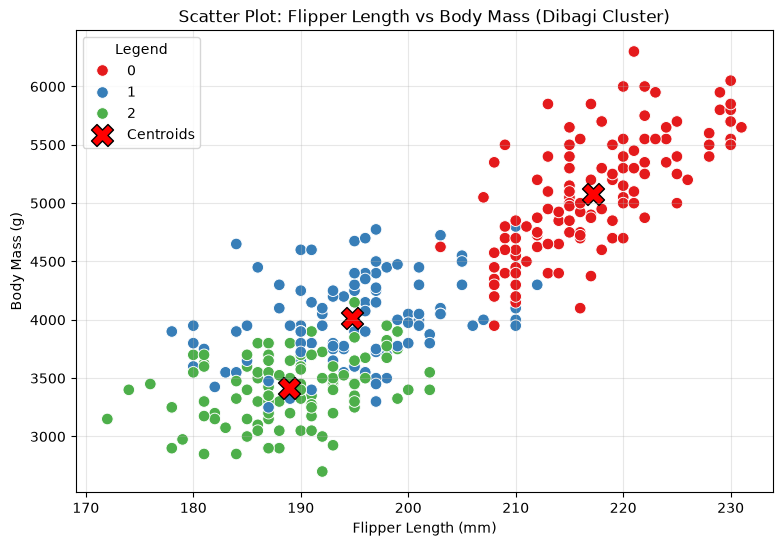

In [118]:
centroids_scaled = np.array(kmeans_model.centroids)
centroids_asli = (centroids_scaled * std_X.to_numpy()) + mean_X.to_numpy()
df_centroids = pd.DataFrame(centroids_asli, columns=kolom_fitur)

print("=== Tabel Posisi Centroid pada Skala Fisik Asli ===")
print(df_centroids.round(2))

print("\n=== Profil Rata-Rata Fisik Penguin Tiap Cluster ===")
print(df.groupby('Cluster')[kolom_numerik].mean().round(2))

print("\n=== Distribusi Jenis Kelamin (Sex) Tiap Cluster ===")
print(pd.crosstab(df['Cluster'], df['sex']))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, 
    x='flipper_length_mm', 
    y='body_mass_g', 
    hue='Cluster', 
    palette='Set1', 
    s=70
)

plt.scatter(
    df_centroids['flipper_length_mm'], 
    df_centroids['body_mass_g'], 
    marker='X', 
    color='red', 
    s=250, 
    edgecolor='black', 
    label='Centroids'
)

plt.title('Scatter Plot: Flipper Length vs Body Mass (Dibagi Cluster)')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.legend(title='Legend')
plt.grid(True, alpha=0.3)
plt.show()

---
## 7. GUI

In [119]:
def predict_cluster():
    try:
        culmen_length = entryCulmenLength.get().strip()
        culmen_depth = entryCulmenDepth.get().strip()
        flipper_length = entryFlipperLength.get().strip()
        body_mass = entryBodyMass.get().strip()
        sex = segSex.get().strip()

        if not all((culmen_length, culmen_depth,
                    flipper_length, body_mass, sex)):
            raise ValueError("Semua kolom harus diisi.")

        values = [
            float(culmen_length),
            float(culmen_depth),
            float(flipper_length),
            float(body_mass)
        ]

        sex = sex.upper()

        if sex == "FEMALE":
            sex_features = [1, 0, 0]
        elif sex == "MALE":
            sex_features = [0, 1, 0]
        else:
            sex_features = [0, 0, 1]

        input_data = np.array([
            values + sex_features
        ], dtype=float)

        input_scaled = (input_data - mean_X.to_numpy()) / std_X.to_numpy()

        cluster = kmeans_model.predict_new(input_scaled)[0]

        lblPredict.configure(
            text=f"Hasil Prediksi: Penguin masuk Cluster {cluster}"
        )

    except ValueError as error:
        lblPredict.configure(text=f"Input tidak valid: {error}")
    except Exception as error:
        lblPredict.configure(text=f"Terjadi kesalahan: {error}")

In [120]:
from customtkinter import *

app = CTk()
app.title('Segmentasi Spesies Penguin')

lebar = 600
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2))
y = int((screen_height / 2) - (tinggi / 2))
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")
set_appearance_mode('light')

Title = CTkLabel(app, text="Analisis Segmentasi Spesies Penguin", font=("Arial", 24, "bold"))
Title.pack(pady=20)

MainFrame = CTkFrame(app, fg_color="#fff",  corner_radius=12)
MainFrame.pack(padx=10, pady=(0, 20), fill="both", expand=True)

lblCulmenLength = CTkLabel(MainFrame, text="Panjang Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenLength.pack(pady=(20, 5), padx=20, anchor="w")
entryCulmenLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Paruh Penguin (e.g. 39.5)")
entryCulmenLength.pack(padx=20, pady=(0, 20), fill="both")

lblCulmenDepth = CTkLabel(MainFrame, text="Kedalaman Paruh Penguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblCulmenDepth.pack(padx=20, pady=(0,5), anchor="w")
entryCulmenDepth = CTkEntry(MainFrame, placeholder_text="Masukkan Kedalaman Paruh Penguin (e.g. 17.4)")
entryCulmenDepth.pack(padx=20, pady=(0, 20), fill="both")

lblFlipperLength = CTkLabel(MainFrame, text="Panjang Sirip Pinguin (Satuan: milimeter)", font=("Arial", 16), justify="left")
lblFlipperLength.pack(padx=20, pady=(0,5), anchor="w")
entryFlipperLength = CTkEntry(MainFrame, placeholder_text="Masukkan Panjang Sirip Penguin (e.g. 186)")
entryFlipperLength.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Berat Badan Pinguin (Satuan: gram)", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
entryBodyMass = CTkEntry(MainFrame, placeholder_text="Masukkan Berat Badan Penguin (e.g. 3800)")
entryBodyMass.pack(padx=20, pady=(0, 20), fill="both")

lblBodyMass = CTkLabel(MainFrame, text="Jenis Kelamin Pinguin", font=("Arial", 16), justify="left")
lblBodyMass.pack(padx=20, pady=(0,5), anchor="w")
segSex = CTkSegmentedButton(MainFrame, values=["Male", "Female"], fg_color="#fff")
segSex.pack(padx=20, pady=(0, 20), fill="both")

btnPredict = CTkButton(app, text="Prediksi Kelompok Penguin", font=("Arial", 16), command=predict_cluster)
btnPredict.pack(padx=20, pady=(20,5), fill="both")

lblPredict = CTkLabel(app, text="Hasil Prediksi: -", font=("Arial", 16), justify="center")
lblPredict.pack(padx=20, pady=(0, 30), fill="x")

app.mainloop()

invalid command name "140122168434048update"
    while executing
"140122168434048update"
    ("after" script)
invalid command name "140122168960896check_dpi_scaling"
    while executing
"140122168960896check_dpi_scaling"
    ("after" script)


---
## 8. Conclution

### 8.1 Kesimpulan Analisis dan Pemodelan

Berdasarkan rangkaian eksplorasi data, prapemrosesan, hingga pemodelan yang telah dilakukan pada dataset morfologi penguin, diperoleh beberapa kesimpulan utama sebagai berikut:
1. Dataset awal penguins.csv berjumlah 344 baris dan 5 kolom, di mana ditemukan 18 nilai kosong (missing value), 1 baris data duplikat, serta anomali outlier ekstrem pada atribut flipper_length_mm (nilai minimum -132.0 mm dan maksimum 5000.0 mm) yang harus dibersihkan agar tidak mendistorsi proses pemodelan.